# 05 - Player-level features: does knowing the playing XI help?

**The question.** Notebooks 03 and 04 know only the *match state* (runs, wickets, rates) and the *era / venue*.
They cannot tell a team full of power hitters from a team of grafters, or a strong bowling attack from a weak one.
This notebook tests whether the **playing XI** (`info.players`) adds predictive power, and whether it helps *during* the innings
by knowing **which batters are still to come**.

## How player strength is measured (leak-safe, era-neutral)
For every player, using **only matches before the current date**:
* **Batting ability** = (runs scored - balls faced x the average batter's runs per ball in the same innings) / (balls faced + 150).
  "Runs per ball above what an average batter did in the same innings." The +150 shrinks players with few balls toward average (0).
* **Bowling ability (runs)** = (runs conceded - balls bowled x the average bowler's runs per ball in the same innings) / (balls bowled + 150). Negative = tight bowler.
* **Bowling ability (wickets)** = (wickets - balls bowled x innings wicket rate) / (balls bowled + 150).
* **Expected workload** = shrunk average balls faced / bowled per match (so an opener counts more than a No. 10).

Team features are `ability x workload` summed over the XI: *"this XI is worth about +X runs versus a typical XI"*.
Dynamic feature: **remaining batting skill** = ball-weighted batting ability of the XI batters **not yet dismissed**.

## What we test (same folds as before: validate 2021-25, holdout 2026 once)
| Task | Baseline | With XI |
|------|----------|---------|
| A. Pre-match first-innings total | league average + era-adjusted venue (notebook 03) | + batting XI, opposition bowling XI |
| B. Live first-innings total (by over) | Ridge on match state (notebook 03) | + static XI strength, + remaining batters |
| C. Live chase win probability (by over) | Logistic on match state (notebook 04) | + static XI strength, + remaining batters |

Every comparison is paired by match with a bootstrap CI. **Expect small gains**: player quality is a second-order effect
next to the match state, and a gain of 1-2 runs can be real or noise. The CIs decide.

In [1]:
import os, re, warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path(os.environ.get("IPL_PROJECT_ROOT", Path.cwd().parent))
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("YAML files  :", len(list(RAW_DATA_DIR.glob("*.yaml"))))

Project root: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab
YAML files  : 1243


## 1. Parse both innings, player lines, XIs and results

In [2]:
NOT_A_WICKET = {"retired hurt", "retired not out"}      # not a lost wicket
BOWLER_WICKET_KINDS = {"bowled", "caught", "lbw", "stumped", "caught and bowled", "hit wicket"}   # credited to the bowler


def iter_raw_deliveries(innings_data):
    if "deliveries" in innings_data:                       # layout used by your files
        for entry in innings_data["deliveries"]:
            if isinstance(entry, dict) and entry:
                yield next(iter(entry.values()))
    elif "overs" in innings_data:                          # newer layout
        for over in innings_data["overs"]:
            for d in over.get("deliveries", []):
                yield d
    else:
        raise ValueError("Unknown innings layout: %s" % list(innings_data))


def parse_delivery(d, reg):
    # reg maps player name -> unique id (info.registry.people); falls back to the name itself
    runs = d.get("runs") or {}
    extras = d.get("extras") or {}
    wk = d.get("wickets")
    if wk is None:
        w = d.get("wicket")
        wk = [w] if isinstance(w, dict) else []
    wk = [w for w in wk if w.get("kind") not in NOT_A_WICKET]
    pid = lambda n: reg.get(n, n)
    batter_runs = runs.get("batter", runs.get("batsman", 0)) or 0
    wides, noballs = extras.get("wides", 0) or 0, extras.get("noballs", 0) or 0
    return {
        "total": runs.get("total", 0) or 0, "batter_runs": batter_runs, "wide": wides, "noball": noballs,
        "wickets": len(wk), "out": [pid(w["player_out"]) for w in wk if w.get("player_out")],
        "bowler_wkts": sum(1 for w in wk if w.get("kind") in BOWLER_WICKET_KINDS),
        "bat": pid(d.get("batsman", d.get("batter"))), "bowl": pid(d.get("bowler")),
        "runs_vs_bowler": batter_runs + wides + noballs,          # byes / leg-byes are not charged to the bowler
    }


def summarise_innings(dels):
    # over-end states {k: (runs, wickets, boundaries, dismissed_player_ids)} + per-player batting / bowling lines
    runs = wkts = bnd = legal = bw_wk = 0
    out, states, batters, bowlers = set(), {}, {}, {}
    for d in dels:
        runs += d["total"]; wkts += d["wickets"]; out.update(d["out"]); bw_wk += d["bowler_wkts"]
        if d["batter_runs"] in (4, 6) and d["wide"] == 0:
            bnd += 1
        if d["wide"] == 0:                                        # a ball faced by the batter
            b = batters.setdefault(d["bat"], [0, 0]); b[0] += 1; b[1] += d["batter_runs"]
        bw = bowlers.setdefault(d["bowl"], [0, 0, 0]); bw[1] += d["runs_vs_bowler"]; bw[2] += d["bowler_wkts"]
        if d["wide"] == 0 and d["noball"] == 0:                   # a legal ball
            legal += 1; bw[0] += 1
            if legal % 6 == 0:
                states[legal // 6] = (runs, wkts, bnd, frozenset(out))
    bat_balls = sum(v[0] for v in batters.values())
    return dict(states=states, runs=runs, wkts=wkts, legal=legal, batters=batters, bowlers=bowlers, bowler_wkts=bw_wk,
                bat_rr=(sum(v[1] for v in batters.values()) / bat_balls) if bat_balls else 0.0,       # batter runs per ball faced
                bowl_rr=(sum(v[1] for v in bowlers.values()) / legal) if legal else 0.0)              # runs charged to bowlers per legal ball


def get_innings(match):
    out = []
    for entry in match.get("innings", []):
        if "team" in entry:                                       # newer layout
            if not entry.get("super_over"):
                out.append(entry)
        else:                                                     # layout used by your files: {"1st innings": {...}}
            name, data = next(iter(entry.items()))
            if name in ("1st innings", "2nd innings"):
                out.append(data)
    return out[:2]


def load_all(raw_dir):
    rows, parsed, names, errors = [], {}, {}, []
    for path in sorted(raw_dir.glob("*.yaml")):
        try:
            with path.open("r", encoding="utf-8") as f:
                match = yaml.safe_load(f)
            info = match["info"]
            reg = (info.get("registry") or {}).get("people") or {}
            for n, i in reg.items():
                names[i] = n
            oc = info.get("outcome") or {}
            row = {"match_id": path.stem, "date": pd.to_datetime(str(info["dates"][0])),
                   "venue_raw": info.get("venue"), "scheduled_overs": info.get("overs", 20),
                   "winner": oc.get("winner"), "method": oc.get("method"), "result": oc.get("result")}
            xi = {team: [reg.get(p, p) for p in plist] for team, plist in (info.get("players") or {}).items()}
            inns = get_innings(match)
            if len(inns) == 2:
                s = [summarise_innings([parse_delivery(d, reg) for d in iter_raw_deliveries(x)]) for x in inns]
                row.update(team1=inns[0].get("team"), team2=inns[1].get("team"),
                           final_score=s[0]["runs"], first_wkts=s[0]["wkts"], first_legal=s[0]["legal"],
                           second_total=s[1]["runs"], second_wkts=s[1]["wkts"], second_legal=s[1]["legal"])
                parsed[path.stem] = dict(date=row["date"], xi=xi, inn=s, team1=row["team1"], team2=row["team2"])
            rows.append(row)
        except Exception as exc:
            errors.append((path.name, repr(exc)))
    return pd.DataFrame(rows), parsed, names, errors


raw_matches, parsed, player_names, load_errors = load_all(RAW_DATA_DIR)
print("Matches parsed :", len(raw_matches), "| with both innings:", len(parsed))
print("Players named  :", len(player_names))
print("Load errors    :", len(load_errors), load_errors[:3])

Matches parsed : 1243 | with both innings: 1237
Players named  : 964
Load errors    : 0 []


## 2. Usable matches and venue names

In [3]:
def status(r):
    if pd.isna(r.get("team2")):
        return "missing an innings"
    if r["scheduled_overs"] != 20:
        return "not a 20-over match"
    if pd.notna(r["method"]):
        return "rain-adjusted target (D/L or similar)"
    if not (r["first_legal"] >= 120 or r["first_wkts"] >= 10):
        return "first innings curtailed"
    if r["result"] in ("tie", "no result") or pd.isna(r["winner"]) or r["second_total"] == r["final_score"]:
        return "tie / no result"
    if (r["second_total"] > r["final_score"]) != (r["winner"] == r["team2"]):
        return "label mismatch (scores vs outcome)"
    return "ok"


raw_matches["status"] = raw_matches.apply(status, axis=1)
print(raw_matches["status"].value_counts().to_string())

matches = raw_matches[raw_matches["status"] == "ok"].copy()
matches["chase_won"] = (matches["second_total"] > matches["final_score"]).astype(int)
matches["target"] = matches["final_score"] + 1
matches["season"] = matches["date"].dt.year

VENUE_ALIASES = {
    "feroz shah kotla": "Arun Jaitley Stadium",
    "sardar patel stadium": "Narendra Modi Stadium",
    "sheikh zayed stadium": "Zayed Cricket Stadium",
    "punjab cricket association stadium": "Punjab Cricket Association IS Bindra Stadium",
    "punjab cricket association is bindra stadium": "Punjab Cricket Association IS Bindra Stadium",
    "subrata roy sahara stadium": "Maharashtra Cricket Association Stadium",
}

def standardize_venue(v):
    if not isinstance(v, str):
        return "Unknown"
    key = re.sub(r"\s+", " ", v.split(",")[0].replace(".", " ")).strip().lower()
    return VENUE_ALIASES.get(key, re.sub(r"\s+", " ", v.split(",")[0].replace(".", " ")).strip())

matches["venue"] = matches["venue_raw"].map(standardize_venue)
print("\nUsable matches:", len(matches), "| venue labels: raw %d -> standardised %d" % (
    matches["venue_raw"].nunique(), matches["venue"].nunique()))

status
ok                                       1183
rain-adjusted target (D/L or similar)      23
tie / no result                            18
first innings curtailed                    13
missing an innings                          6

Usable matches: 1183 | venue labels: raw 60 -> standardised 36


## 3. Leak-safe pre-match context (league average, era-adjusted venue, chase rate)

In [4]:
def add_prior_context(df, league_window=60, chase_window=100, venue_shrink=5.0, fallback=160.0):
    m = df.sort_values(["date", "match_id"]).reset_index(drop=True).copy()
    dates = m["date"].to_numpy()
    totals = m["final_score"].to_numpy(dtype=float)
    chase = m["chase_won"].to_numpy(dtype=float)
    venues = m["venue"].to_numpy()
    n_all = len(m)
    league, chase_rate = np.empty(n_all), np.empty(n_all)
    for i in range(n_all):
        prior = np.flatnonzero(dates < dates[i])                 # strictly earlier dates only
        recent = totals[prior][-league_window:]
        league[i] = recent.mean() if len(recent) >= 5 else fallback
        rc = chase[prior][-chase_window:]
        chase_rate[i] = rc.mean() if len(rc) >= 20 else 0.5
    excess = totals - league
    venue_effect, venue_n = np.empty(n_all), np.empty(n_all, dtype=int)
    for i in range(n_all):
        prior = np.flatnonzero(dates < dates[i])
        sv = prior[venues[prior] == venues[i]]
        venue_n[i] = len(sv)
        venue_effect[i] = excess[sv].sum() / (len(sv) + venue_shrink)
    m["league_recent"], m["excess"] = league, excess
    m["venue_effect"], m["venue_n"], m["chase_rate_recent"] = venue_effect, venue_n, chase_rate
    return m


matches = add_prior_context(matches)
TOTAL_OVERS = 20

matches[['venue', 'final_score', 'league_recent', 'venue_effect']].tail(3).round(1)

,venue,final_score,league_recent,venue_effect
1180,Maharaja Yadavindra Singh International Cricke...,243.0,197.4,-6.4
1181,Maharaja Yadavindra Singh International Cricke...,214.0,198.8,-3.9
1182,Narendra Modi Stadium,155.0,198.9,2.0


## 4. Player history and team strength (strictly earlier dates)
Matches are processed **date by date**: features for every match of a day are computed *before* that day's matches are added to history,
so same-day matches never see each other.

In [5]:
K_BAT = K_BOWL = 150.0           # shrinkage: balls of "average" evidence added to every player
M_SHRINK, AVG_BALLS = 3.0, 10.0  # workload shrinkage: 3 matches of average (10 balls) usage


def new_hist():
    return {"played": 0, "bat_balls": 0.0, "bat_exc": 0.0, "bowl_balls": 0.0, "bowl_run_exc": 0.0, "bowl_wk_exc": 0.0}


def skills(h):
    a_bat = h["bat_exc"] / (h["bat_balls"] + K_BAT)
    e_bat = (h["bat_balls"] + M_SHRINK * AVG_BALLS) / (h["played"] + M_SHRINK)
    a_run = h["bowl_run_exc"] / (h["bowl_balls"] + K_BOWL)
    a_wk = h["bowl_wk_exc"] / (h["bowl_balls"] + K_BOWL)
    e_bowl = (h["bowl_balls"] + M_SHRINK * AVG_BALLS) / (h["played"] + M_SHRINK)
    return a_bat, e_bat, a_run, a_wk, e_bowl


def team_skill(xi, hist):
    if not xi:
        return dict(bat_pairs={}, bat_excess=np.nan, bowl_run_excess=np.nan, bowl_wk_excess=np.nan, experience=np.nan)
    pairs, be, br, bw, played = {}, 0.0, 0.0, 0.0, []
    for p in xi:
        h = hist[p] if p in hist else new_hist()
        a_bat, e_bat, a_run, a_wk, e_bowl = skills(h)
        pairs[p] = (a_bat, e_bat)
        be += a_bat * e_bat
        br += a_run * e_bowl
        bw += a_wk * e_bowl
        played.append(h["played"])
    return dict(bat_pairs=pairs, bat_excess=be, bowl_run_excess=br, bowl_wk_excess=bw, experience=float(np.mean(played)))


def update_history(p, hist):
    for team in (p["team1"], p["team2"]):
        for pid in p["xi"].get(team, []):
            if pid not in hist:
                hist[pid] = new_hist()
            hist[pid]["played"] += 1
    for inn in p["inn"]:
        if inn["legal"] == 0:
            continue
        wk_rate = inn["bowler_wkts"] / inn["legal"]
        for pid, (balls, runs) in inn["batters"].items():
            h = hist.setdefault(pid, new_hist())
            h["bat_balls"] += balls
            h["bat_exc"] += runs - balls * inn["bat_rr"]          # vs the average batter in the same innings
        for pid, (balls, conceded, wk) in inn["bowlers"].items():
            h = hist.setdefault(pid, new_hist())
            h["bowl_balls"] += balls
            h["bowl_run_exc"] += conceded - balls * inn["bowl_rr"]
            h["bowl_wk_exc"] += wk - balls * wk_rate


def build_player_features(raw_matches, parsed):
    order = raw_matches[raw_matches["match_id"].isin(parsed)].sort_values(["date", "match_id"])
    hist, feats = {}, {}
    for date, grp in order.groupby("date", sort=True):
        for mid in grp["match_id"]:                               # 1) features from history BEFORE this date
            p = parsed[mid]
            feats[mid] = {"t1": team_skill(p["xi"].get(p["team1"], []), hist),
                          "t2": team_skill(p["xi"].get(p["team2"], []), hist)}
        for mid in grp["match_id"]:                               # 2) only then add this date's matches to history
            update_history(parsed[mid], hist)
    return feats, hist


player_feats, final_hist = build_player_features(raw_matches, parsed)

pm = matches.copy()
for col, (side, key) in {"xi1_bat": ("t1", "bat_excess"), "xi1_bowl_runs": ("t1", "bowl_run_excess"),
                         "xi1_bowl_wkts": ("t1", "bowl_wk_excess"), "xi1_exp": ("t1", "experience"),
                         "xi2_bat": ("t2", "bat_excess"), "xi2_bowl_runs": ("t2", "bowl_run_excess"),
                         "xi2_bowl_wkts": ("t2", "bowl_wk_excess"), "xi2_exp": ("t2", "experience")}.items():
    pm[col] = pm["match_id"].map(lambda m: player_feats[m][side][key])
print("Matches with a recorded XI for both teams: %d of %d" % (
    pm[["xi1_bat", "xi2_bat"]].notna().all(axis=1).sum(), len(pm)))
pm[["season", "xi1_bat", "xi2_bowl_runs", "xi2_bowl_wkts", "xi1_exp"]].describe().round(2)

Matches with a recorded XI for both teams: 1183 of 1183


,season,xi1_bat,xi2_bowl_runs,xi2_bowl_wkts,xi1_exp
count,1183.00,1183.00,1183.00,1183.00,1183.00
mean,2017.27,2.10,-1.86,0.11,49.13
std,5.54,2.48,2.70,0.23,23.27
min,2008.00,-5.68,-9.80,-0.61,0.00
25%,2012.00,0.41,-3.77,-0.04,32.30
50%,2017.00,2.04,-1.85,0.13,50.25
75%,2022.00,3.93,0.11,0.27,65.18
max,2026.00,9.30,5.80,0.87,123.09


**Sanity check - do the best-rated players look right?** Players with at least 600 balls faced / bowled, using ALL history (descriptive only, not used for training).

In [6]:
rows = []
for pid, h in final_hist.items():
    a_bat, e_bat, a_run, a_wk, e_bowl = skills(h)
    rows.append(dict(player=player_names.get(pid, pid), matches=h["played"], bat_balls=h["bat_balls"], bat_ability=a_bat,
                     bowl_balls=h["bowl_balls"], bowl_run_ability=a_run, bowl_wk_ability=a_wk))
pl = pd.DataFrame(rows)
print("Top 10 batters: runs per ball above the innings average (higher = better)")
display(pl[pl["bat_balls"] >= 600].sort_values("bat_ability", ascending=False).head(10)[["player", "matches", "bat_balls", "bat_ability"]].round(3).reset_index(drop=True))
print("Top 10 bowlers by runs conceded per ball below average (more negative = tighter)")
display(pl[pl["bowl_balls"] >= 600].sort_values("bowl_run_ability").head(10)[["player", "matches", "bowl_balls", "bowl_run_ability", "bowl_wk_ability"]].round(3).reset_index(drop=True))
print("Top 10 wicket-takers by wickets per ball above average")
display(pl[pl["bowl_balls"] >= 600].sort_values("bowl_wk_ability", ascending=False).head(10)[["player", "matches", "bowl_balls", "bowl_run_ability", "bowl_wk_ability"]].round(4).reset_index(drop=True))

Top 10 batters: runs per ball above the innings average (higher = better)


,player,matches,bat_balls,bat_ability
0,AD Russell,139,1522.0,0.299
1,TH David,66,650.0,0.230
2,N Pooran,103,1509.0,0.204
3,V Sehwag,104,1755.0,0.197
4,Harbhajan Singh,163,604.0,0.174
5,AB de Villiers,182,3358.0,0.170
6,KA Pollard,189,2316.0,0.158
7,YK Pathan,174,2241.0,0.153
8,SP Narine,201,1101.0,0.148
9,GJ Maxwell,141,1817.0,0.145


Top 10 bowlers by runs conceded per ball below average (more negative = tighter)


,player,matches,bowl_balls,bowl_run_ability,bowl_wk_ability
0,SP Narine,201,4651.0,-0.232,-0.004
1,Rashid Khan,153,3530.0,-0.183,-0.000
2,JJ Bumrah,158,3631.0,-0.183,0.004
3,AR Patel,175,3567.0,-0.180,-0.009
4,M Muralitharan,66,1524.0,-0.173,-0.005
5,MJ Santner,35,687.0,-0.161,-0.006
6,JC Archer,68,1578.0,-0.158,0.009
7,A Kumble,42,965.0,-0.152,0.005
8,Noor Ahmad,51,1098.0,-0.148,0.003
9,DL Vettori,34,777.0,-0.148,-0.006


Top 10 wicket-takers by wickets per ball above average


,player,matches,bowl_balls,bowl_run_ability,bowl_wk_ability
0,AD Russell,139,1806.0,0.1163,0.0197
1,L Ngidi,28,620.0,-0.1058,0.0165
2,AJ Tye,30,684.0,-0.0248,0.0140
3,K Rabada,101,2290.0,0.0269,0.0128
4,M Pathirana,32,690.0,-0.0156,0.0122
5,Mohsin Khan,30,654.0,-0.1212,0.0118
6,SL Malinga,122,2827.0,-0.0855,0.0116
7,Imran Tahir,59,1316.0,-0.0343,0.0113
8,CH Morris,81,1720.0,-0.0136,0.0098
9,PWH de Silva,37,798.0,-0.0708,0.0098


## 5. Snapshot tables (one row per match and over) with XI features
* First innings: static XI strength (batting XI, opposition bowling XI) and **remaining batting skill** = batters not yet dismissed.
* Chase: chasing XI batting strength, defending XI bowling strength, and remaining chasing batters.

In [7]:
# ---------------- first-innings (score) snapshot features: same as notebook 03 ----------------
def first_features(states, k):
    def at(j):
        return states[j][:3] if j >= 1 else (0, 0, 0)
    runs, wkts, bnd = states[k][:3]
    r5, w5, _ = at(k - 5)
    r3, _, _ = at(k - 3)
    pp_runs, pp_wkts, _ = at(min(k, 6))
    return {
        "over": k, "overs_left": TOTAL_OVERS - k, "runs": runs, "wickets": wkts, "wickets_in_hand": 10 - wkts,
        "run_rate": runs / k, "runs_last5": runs - r5, "wkts_last5": wkts - w5, "rr_last5": (runs - r5) / min(k, 5),
        "boundaries": bnd, "pp_runs": pp_runs, "pp_wkts": pp_wkts, "rr_last3": (runs - r3) / min(k, 3),
        "phase": 0 if k <= 6 else (1 if k <= 15 else 2), "hand_x_rr": (10 - wkts) * runs / k,
    }


def add_linear_first(df):
    df = df.copy()
    L = df["overs_left"]
    df["crr_remaining"] = df["run_rate"] * L
    df["form_remaining"] = df["rr_last5"] * L
    df["form3_remaining"] = df["rr_last3"] * L
    df["league_remaining"] = df["league_recent"] / TOTAL_OVERS * L
    df["venue_remaining"] = df["venue_effect"] / TOTAL_OVERS * L
    df["hand_x_left"] = df["wickets_in_hand"] * L
    df["hand_x_crr_rem"] = df["wickets_in_hand"] * df["crr_remaining"] / 10
    df["phase_mid"] = (df["phase"] == 1).astype(int)
    df["phase_death"] = (df["phase"] == 2).astype(int)
    return df


FIRST_RAW = ["over", "overs_left", "runs", "wickets", "wickets_in_hand", "run_rate", "runs_last5", "wkts_last5",
             "rr_last5", "boundaries", "venue_effect", "venue_n", "league_recent", "pp_runs", "pp_wkts",
             "rr_last3", "phase", "hand_x_rr"]
FIRST_LIN = FIRST_RAW + ["crr_remaining", "form_remaining", "form3_remaining", "league_remaining",
                         "venue_remaining", "hand_x_left", "hand_x_crr_rem", "phase_mid", "phase_death"]


class RidgeFirst:
    # Ridge on 'remaining runs'; prediction = runs so far + remaining
    name = "Ridge (match state only)"
    feats = FIRST_LIN
    def fit(self, tr):
        self.m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))
        self.m.fit(tr[self.feats], tr["remaining"])
        return self
    def predict_final(self, df): return df["runs"].to_numpy() + self.m.predict(df[self.feats])

# ---------------- chase (win probability) features: same as notebook 04 ----------------
def chase_features(states, k, target):
    def at(j):
        return states[j][:3] if j >= 1 else (0, 0, 0)
    runs, wkts, _ = states[k][:3]
    r5, w5, _ = at(k - 5)
    r3, _, _ = at(k - 3)
    pp_runs, pp_wkts, _ = at(min(k, 6))
    left = TOTAL_OVERS - k
    need = target - runs
    hand = 10 - wkts
    crr, rr5, rr3 = runs / k, (runs - r5) / min(k, 5), (runs - r3) / min(k, 3)
    rrr = need / left
    return {
        "over": k, "overs_left": left, "runs": runs, "wickets": wkts, "wickets_in_hand": hand,
        "target": target, "runs_needed": need, "rrr": rrr, "crr": crr, "rrr_minus_crr": rrr - crr,
        "rr_last5": rr5, "rr_last3": rr3, "wkts_last5": wkts - w5,
        "pp_runs": pp_runs, "pp_wkts": pp_wkts, "phase": 0 if k <= 6 else (1 if k <= 15 else 2),
        "need_per_wicket": need / max(hand, 1),
        "gap_crr": need - crr * left, "gap_form5": need - rr5 * left, "gap_form3": need - rr3 * left,
    }


def add_derived_chase(df):
    df = df.copy()
    df["target_vs_league"] = df["target"] - df["league_recent"]
    df["hand_x_left"] = df["wickets_in_hand"] * df["overs_left"]
    df["hand_x_rrr"] = df["wickets_in_hand"] * df["rrr"] / 10
    df["rrr_sq"] = df["rrr"] ** 2 / 10
    df["phase_mid"] = (df["phase"] == 1).astype(int)
    df["phase_death"] = (df["phase"] == 2).astype(int)
    return df


CHASE_RAW = ["over", "overs_left", "runs", "wickets", "wickets_in_hand", "target", "runs_needed", "rrr", "crr",
             "rrr_minus_crr", "rr_last5", "rr_last3", "wkts_last5", "pp_runs", "pp_wkts", "phase",
             "need_per_wicket", "gap_crr", "gap_form5", "gap_form3",
             "league_recent", "target_vs_league", "venue_effect", "venue_n", "chase_rate_recent"]
CHASE_LIN = CHASE_RAW + ["hand_x_left", "hand_x_rrr", "rrr_sq", "phase_mid", "phase_death"]
EPS = 1e-4


class LogisticChase:
    name = "Logistic (match state only)"
    feats, C = CHASE_LIN, 0.5
    def fit(self, tr):
        self.m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                               LogisticRegression(C=self.C, max_iter=2000))
        self.m.fit(tr[self.feats], tr["y"])
        return self
    def predict_proba1(self, df): return np.clip(self.m.predict_proba(df[self.feats])[:, 1], EPS, 1 - EPS)


XI_STATIC = ["xi_bat_excess", "xi_bowl_runs", "xi_bowl_wkts"]
XI_DYNAMIC = ["rem_bat_rate", "rem_bat_x_left"]


def remaining_rate(pairs, dismissed):
    num = den = 0.0
    for pid, (a, e) in pairs.items():
        if pid not in dismissed:
            num += a * e
            den += e
    return num / den if den > 0 else np.nan


def build_snapshots(matches, parsed, feats, innings_idx, overs=range(1, TOTAL_OVERS)):
    rows = []
    bat_side, bowl_side = ("t1", "t2") if innings_idx == 0 else ("t2", "t1")
    for r in matches.itertuples():
        inn = parsed[r.match_id]["inn"][innings_idx]
        f_m = feats[r.match_id]
        pairs = f_m[bat_side]["bat_pairs"]
        for k in overs:
            if k not in inn["states"]:
                continue
            runs, wkts = inn["states"][k][:2]
            if innings_idx == 0:
                f = first_features(inn["states"], k)
            else:
                if runs >= r.target or wkts >= 10:                 # chase already decided
                    continue
                f = chase_features(inn["states"], k, r.target)
                f["y"] = r.chase_won
            f.update(match_id=r.match_id, date=r.date, season=r.season, final_score=r.final_score,
                     league_recent=r.league_recent, venue_effect=r.venue_effect, venue_n=r.venue_n,
                     chase_rate_recent=r.chase_rate_recent,
                     xi_bat_excess=f_m[bat_side]["bat_excess"], xi_bowl_runs=f_m[bowl_side]["bowl_run_excess"],
                     xi_bowl_wkts=f_m[bowl_side]["bowl_wk_excess"],
                     rem_bat_rate=remaining_rate(pairs, inn["states"][k][3]))
            rows.append(f)
    df = pd.DataFrame(rows)
    df["rem_bat_x_left"] = df["rem_bat_rate"] * df["overs_left"]
    if innings_idx == 0:
        df["remaining"] = df["final_score"] - df["runs"]
        return add_linear_first(df)
    return add_derived_chase(df)


snap1 = build_snapshots(matches, parsed, player_feats, 0)
snap2 = build_snapshots(matches, parsed, player_feats, 1)
print("First-innings rows:", len(snap1), "| chase rows:", len(snap2))
print("Share of rows with a remaining-batters value: first innings %.2f, chase %.2f" % (
    snap1["rem_bat_rate"].notna().mean(), snap2["rem_bat_rate"].notna().mean()))

First-innings rows: 22405 | chase rows: 21214
Share of rows with a remaining-batters value: first innings 1.00, chase 1.00


## 6. Leak tests (these must pass before any result is trusted)

In [8]:
import copy
rng = np.random.default_rng(0)


def corrupt_match(p):
    q = dict(p)
    q["inn"] = [dict(inn,
                     batters={k: [v[0], v[1] * 10 + 50] for k, v in inn["batters"].items()},
                     bowlers={k: [v[0], v[1] * 10 + 50, v[2] + 5] for k, v in inn["bowlers"].items()})
                for inn in p["inn"]]
    return q


def same(a, b):
    ka = (a["bat_excess"], a["bowl_run_excess"], a["bowl_wk_excess"], a["experience"])
    kb = (b["bat_excess"], b["bowl_run_excess"], b["bowl_wk_excess"], b["experience"])
    return np.allclose(np.array(ka, float), np.array(kb, float), equal_nan=True) and a["bat_pairs"] == b["bat_pairs"]


# (a) player features of a match must not change if its own and every LATER match's player lines are corrupted
order = raw_matches[raw_matches["match_id"].isin(parsed)].sort_values(["date", "match_id"])
probe_id = order["match_id"].iloc[len(order) // 2]
probe_date = order.set_index("match_id").loc[probe_id, "date"]
parsed_c = dict(parsed)
for mid in order[order["date"] >= probe_date]["match_id"]:
    parsed_c[mid] = corrupt_match(parsed[mid])
feats_c, _ = build_player_features(raw_matches, parsed_c)
assert same(player_feats[probe_id]["t1"], feats_c[probe_id]["t1"]) and same(player_feats[probe_id]["t2"], feats_c[probe_id]["t2"])
print("OK: player features use only matches before the match date (own + later matches corrupted, features unchanged)")

# (b) same-day matches must not see each other
day_counts = order.groupby("date").size()
multi = day_counts[day_counts > 1].index
if len(multi):
    d0 = multi[0]
    a_id, b_id = order[order["date"] == d0]["match_id"].iloc[:2]
    parsed_d = dict(parsed)
    parsed_d[a_id] = corrupt_match(parsed[a_id])
    feats_d, _ = build_player_features(raw_matches, parsed_d)
    assert same(player_feats[b_id]["t1"], feats_d[b_id]["t1"]) and same(player_feats[b_id]["t2"], feats_d[b_id]["t2"])
    print("OK: two matches on the same day do not see each other's player data")
else:
    print("(no day with two matches in this data - same-day test skipped)")

# (c) over-k features (incl. dismissed batters) use only balls up to over k
ms = matches.set_index("match_id")
for mid in rng.choice(list(parsed), size=min(40, len(parsed)), replace=False):
    if mid not in ms.index:
        continue
    for idx in (0, 1):
        states = parsed[mid]["inn"][idx]["states"]
        for k in [k for k in (3, 6, 10, 15, 19) if k in states]:
            cut = {j: v for j, v in states.items() if j <= k}
            if idx == 0:
                assert first_features(states, k) == first_features(cut, k), ("future info", mid, k)
            else:
                t = int(ms.loc[mid, "target"])
                assert chase_features(states, k, t) == chase_features(cut, k, t), ("future info", mid, k)
            assert states[k][3] == cut[k][3]
print("OK: over-k features and dismissed-batter sets use only balls up to over k")

# (d) dismissed sets only ever grow
for mid in list(parsed)[:300]:
    for inn in parsed[mid]["inn"]:
        prev = frozenset()
        for k in sorted(inn["states"]):
            assert prev <= inn["states"][k][3]
            prev = inn["states"][k][3]
print("OK: dismissed-batter sets only grow during an innings")

# (e) pre-match context is leak-safe (as in notebooks 03/04)
probe = matches.sort_values("date").iloc[len(matches) // 2]
corrupt = matches.copy()
later = corrupt["date"] >= probe["date"]
corrupt.loc[later, "final_score"] = 999
corrupt.loc[later, "chase_won"] = 1 - corrupt.loc[later, "chase_won"]
a = add_prior_context(matches).set_index("match_id").loc[probe["match_id"]]
b = add_prior_context(corrupt).set_index("match_id").loc[probe["match_id"]]
for col in ("league_recent", "venue_effect", "chase_rate_recent"):
    assert np.isclose(a[col], b[col]), col
print("OK: league / venue / chase-rate context uses only earlier dates")

OK: player features use only matches before the match date (own + later matches corrupted, features unchanged)
OK: two matches on the same day do not see each other's player data
OK: over-k features and dismissed-batter sets use only balls up to over k
OK: dismissed-batter sets only grow during an innings
OK: league / venue / chase-rate context uses only earlier dates


## 7. Folds
Rolling-origin by season (validate 2021-25). 2026 is untouched until section 11. All rows of a match stay on one side.

In [9]:
def per_match_table(preds, over=None, metric="m"):
    t = preds if over is None else preds[preds["over"] == over]
    return t.pivot_table(index="match_id", columns="model", values=metric, aggfunc="mean").dropna()


def boot_mean_ci(x, n_boot=2000, seed=0):
    x = np.asarray(x, dtype=float)
    rng = np.random.default_rng(seed)
    means = x[rng.integers(0, len(x), size=(n_boot, len(x)))].mean(axis=1)
    lo, hi = np.quantile(means, [0.025, 0.975])
    return x.mean(), lo, hi


def compare(preds, pairs, overs, metric="m"):
    # gain = reference error - challenger error, paired by match; positive = challenger better
    rows = []
    for o in overs:
        t = per_match_table(preds, None if o == "ALL" else o, metric)
        for ch, ref in pairs:
            gain, lo, hi = boot_mean_ci((t[ref] - t[ch]).to_numpy())
            verdict = "challenger better" if lo > 0 else ("reference better" if hi < 0 else "noise")
            rows.append(dict(over=o, challenger=ch, reference=ref, n_matches=len(t),
                             gain=gain, ci_lo=lo, ci_hi=hi, verdict=verdict))
    return pd.DataFrame(rows)


def show_compare(df, unit):
    for (ch, ref), g in df.groupby(["challenger", "reference"], sort=False):
        print("\n%s  vs  %s   (gain = reference %s - challenger %s; 95%% match-bootstrap CI)" % (ch, ref, unit, unit))
        display(g.drop(columns=["challenger", "reference"]).set_index("over").round(3))

FOLD_YEARS = [2021, 2022, 2023, 2024, 2025]
HOLDOUT_START = 2026
CHECKPOINTS = [1, 3, 6, 10, 15, 18]
folds = [{"train_through": y - 1, "validate": y} for y in FOLD_YEARS if (snap1["season"] == y).any()]
print("folds:", [f["validate"] for f in folds], "| holdout seasons >=", HOLDOUT_START)
for name, s in (("first innings", snap1), ("chase", snap2)):
    dev_ids = set(s[s["season"] < HOLDOUT_START]["match_id"]); ho_ids = set(s[s["season"] >= HOLDOUT_START]["match_id"])
    assert not (dev_ids & ho_ids)
print("OK: development and holdout never share a match")

folds: [2021, 2022, 2023, 2024, 2025] | holdout seasons >= 2026
OK: development and holdout never share a match


## 8. Task A - pre-match first-innings total
Baseline: `league_recent + venue_effect` (the best pre-match guess from notebook 03). With XI: a small Ridge learns how much the
batting XI and the opposition bowling XI move the score *away* from that baseline.

In [10]:
XI_PM = ["xi1_bat", "xi2_bowl_runs", "xi2_bowl_wkts", "xi1_exp", "xi2_exp"]
pm["base_pred"] = pm["league_recent"] + pm["venue_effect"]
pm["resid"] = pm["final_score"] - pm["base_pred"]
pm_dev = pm[pm["season"] < HOLDOUT_START]
pm_hold = pm[pm["season"] >= HOLDOUT_START]

print("Correlation of each XI feature with the miss of the baseline (development matches):")
print(pm_dev[XI_PM + ["resid"]].corr()["resid"].drop("resid").round(3).to_string())
print("\nExpected signs: xi1_bat > 0 (stronger batters -> higher score); xi2_bowl_runs > 0 (a leakier attack concedes more runs);\n"
      "xi2_bowl_wkts < 0 (a wicket-taking attack lowers the score). Correlations near 0 mean the XI barely explains the miss.\n")

A_BASE, A_XI = "League + venue (no XI)", "League + venue + XI"


class PreMatchXI:
    def fit(self, tr):
        self.m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=200.0))
        self.m.fit(tr[XI_PM], tr["resid"])
        return self
    def predict(self, df): return df["base_pred"].to_numpy() + self.m.predict(df[XI_PM])


def prematch_preds(data, folds):
    out = []
    for f in folds:
        tr, va = data[data["season"] <= f["train_through"]], data[data["season"] == f["validate"]]
        xi_model = PreMatchXI().fit(tr)
        for name, pred in ((A_BASE, va["base_pred"].to_numpy()), (A_XI, xi_model.predict(va))):
            out.append(pd.DataFrame({"match_id": va["match_id"].to_numpy(), "over": 0, "model": name,
                                     "m": np.abs(pred - va["final_score"].to_numpy())}))
    return pd.concat(out, ignore_index=True)


a_preds = prematch_preds(pm_dev, folds)
print("Pre-match MAE on validation seasons 2021-25 (runs):")
print(a_preds.groupby("model")["m"].mean().round(2).to_string())
a_compare = compare(a_preds, [(A_XI, A_BASE)], overs=[0])
show_compare(a_compare, "MAE (runs)")

Correlation of each XI feature with the miss of the baseline (development matches):
xi1_bat          0.059
xi2_bowl_runs    0.026
xi2_bowl_wkts    0.074
xi1_exp          0.036
xi2_exp         -0.023

Expected signs: xi1_bat > 0 (stronger batters -> higher score); xi2_bowl_runs > 0 (a leakier attack concedes more runs);
xi2_bowl_wkts < 0 (a wicket-taking attack lowers the score). Correlations near 0 mean the XI barely explains the miss.

Pre-match MAE on validation seasons 2021-25 (runs):
model
League + venue (no XI)    26.26
League + venue + XI       26.09

League + venue + XI  vs  League + venue (no XI)   (gain = reference MAE (runs) - challenger MAE (runs); 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
0,342,0.163,-0.162,0.465,noise


## 9. Task B - live first-innings total, by over
Three Ridge models on the same rows: match state only (notebook 03), + static XI strength, + static XI + **remaining batters**.

In [11]:
B0, B1, B2 = "Ridge (match state only)", "Ridge + XI strength", "Ridge + XI + remaining batters"


class RidgeB1(RidgeFirst):
    name, feats = B1, FIRST_LIN + XI_STATIC


class RidgeB2(RidgeFirst):
    name, feats = B2, FIRST_LIN + XI_STATIC + XI_DYNAMIC


MODELS_B = [RidgeFirst, RidgeB1, RidgeB2]
dev1, hold1 = snap1[snap1["season"] < HOLDOUT_START], snap1[snap1["season"] >= HOLDOUT_START]


def first_preds(models, tr_fn, folds, data):
    out = []
    for f in folds:
        tr, va = data[data["season"] <= f["train_through"]], data[data["season"] == f["validate"]]
        for M in models:
            model = M().fit(tr)
            out.append(pd.DataFrame({"match_id": va["match_id"].to_numpy(), "over": va["over"].to_numpy(),
                                     "model": M.name, "m": np.abs(model.predict_final(va) - va["final_score"].to_numpy())}))
    return pd.concat(out, ignore_index=True)


b_preds = first_preds(MODELS_B, None, folds, dev1)
b_mae = b_preds.pivot_table(index="over", columns="model", values="m", aggfunc="mean")
print("Pooled validation MAE (runs) by over, folds 2021-25")
display(b_mae.loc[CHECKPOINTS].round(2))
print("Mean MAE over all overs:")
print(b_preds.groupby("model")["m"].mean().round(3).to_string())

PAIRS_B = [(B1, B0), (B2, B1), (B2, B0)]
b_compare = compare(b_preds, PAIRS_B, overs=CHECKPOINTS + ["ALL"])
show_compare(b_compare, "MAE (runs)")

Pooled validation MAE (runs) by over, folds 2021-25


model,Ridge (match state only),Ridge + XI + remaining batters,Ridge + XI strength
over,,,
1,26.17,26.03,26.04
3,24.51,24.35,24.37
6,21.17,21.09,21.09
10,16.89,16.85,16.81
15,10.42,10.21,10.20
18,7.13,7.06,7.06


Mean MAE over all overs:
model
Ridge (match state only)          16.577
Ridge + XI + remaining batters    16.476
Ridge + XI strength               16.464

Ridge + XI strength  vs  Ridge (match state only)   (gain = reference MAE (runs) - challenger MAE (runs); 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,342,0.128,-0.103,0.358,noise
3,342,0.141,-0.087,0.364,noise
6,342,0.079,-0.149,0.297,noise
10,342,0.085,-0.146,0.295,noise
15,341,0.215,-0.000,0.437,noise
18,335,0.069,-0.156,0.277,noise
ALL,342,0.118,-0.048,0.269,noise



Ridge + XI + remaining batters  vs  Ridge + XI strength   (gain = reference MAE (runs) - challenger MAE (runs); 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,342,0.010,-0.061,0.079,noise
3,342,0.020,-0.056,0.096,noise
6,342,-0.007,-0.094,0.073,noise
10,342,-0.045,-0.121,0.033,noise
15,341,-0.003,-0.075,0.064,noise
18,335,-0.001,-0.066,0.061,noise
ALL,342,-0.012,-0.053,0.029,noise



Ridge + XI + remaining batters  vs  Ridge (match state only)   (gain = reference MAE (runs) - challenger MAE (runs); 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,342,0.138,-0.130,0.397,noise
3,342,0.161,-0.099,0.408,noise
6,342,0.072,-0.176,0.304,noise
10,342,0.040,-0.199,0.257,noise
15,341,0.212,0.003,0.427,challenger better
18,335,0.068,-0.140,0.263,noise
ALL,342,0.106,-0.067,0.260,noise


## 10. Task C - live win probability of the chase, by over
Metric: log loss (lower is better; 0.693 = always 50%). Same three-step comparison.

In [12]:
C0, C1, C2 = "Logistic (match state only)", "Logistic + XI strength", "Logistic + XI + remaining batters"


class LogC1(LogisticChase):
    name, feats = C1, CHASE_LIN + XI_STATIC


class LogC2(LogisticChase):
    name, feats = C2, CHASE_LIN + XI_STATIC + XI_DYNAMIC


MODELS_C = [LogisticChase, LogC1, LogC2]
dev2, hold2 = snap2[snap2["season"] < HOLDOUT_START], snap2[snap2["season"] >= HOLDOUT_START]


def chase_scores(df, p):
    y = df["y"].to_numpy()
    p = np.clip(p, EPS, 1 - EPS)
    return pd.DataFrame({"match_id": df["match_id"].to_numpy(), "over": df["over"].to_numpy(), "y": y, "p": p,
                         "m": -(y * np.log(p) + (1 - y) * np.log(1 - p)), "correct": ((p > 0.5) == (y == 1)).astype(float)})


def chase_preds(models, folds, data):
    out = []
    for f in folds:
        tr, va = data[data["season"] <= f["train_through"]], data[data["season"] == f["validate"]]
        for M in models:
            model = M().fit(tr)
            out.append(chase_scores(va, model.predict_proba1(va)).assign(model=M.name))
    return pd.concat(out, ignore_index=True)


c_preds = chase_preds(MODELS_C, folds, dev2)
c_ll = c_preds.pivot_table(index="over", columns="model", values="m", aggfunc="mean")
print("Pooled validation LOG LOSS by over, folds 2021-25 (lower is better)")
display(c_ll.loc[CHECKPOINTS].round(3))
print("Mean log loss over all overs:")
print(c_preds.groupby("model")["m"].mean().round(4).to_string())
print("Accuracy % (side with p > 50% wins):")
display((100 * c_preds.pivot_table(index="over", columns="model", values="correct", aggfunc="mean").loc[CHECKPOINTS]).round(1))

PAIRS_C = [(C1, C0), (C2, C1), (C2, C0)]
c_compare = compare(c_preds, PAIRS_C, overs=CHECKPOINTS + ["ALL"])
show_compare(c_compare, "log loss")

Pooled validation LOG LOSS by over, folds 2021-25 (lower is better)


model,Logistic (match state only),Logistic + XI + remaining batters,Logistic + XI strength
over,,,
1,0.553,0.556,0.555
3,0.514,0.517,0.516
6,0.494,0.500,0.498
10,0.466,0.472,0.469
15,0.339,0.348,0.343
18,0.288,0.288,0.292


Mean log loss over all overs:
model
Logistic (match state only)          0.4366
Logistic + XI + remaining batters    0.4422
Logistic + XI strength               0.4397
Accuracy % (side with p > 50% wins):


model,Logistic (match state only),Logistic + XI + remaining batters,Logistic + XI strength
over,,,
1,71.3,69.3,70.2
3,71.9,71.6,72.2
6,76.3,76.6,76.0
10,78.6,78.3,78.6
15,85.4,83.9,84.5
18,87.8,87.8,87.8



Logistic + XI strength  vs  Logistic (match state only)   (gain = reference log loss - challenger log loss; 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,342,-0.002,-0.013,0.008,noise
3,342,-0.002,-0.012,0.007,noise
6,342,-0.004,-0.013,0.005,noise
10,336,-0.003,-0.012,0.006,noise
15,322,-0.004,-0.011,0.003,noise
18,263,-0.004,-0.011,0.003,noise
ALL,342,-0.003,-0.011,0.004,noise



Logistic + XI + remaining batters  vs  Logistic + XI strength   (gain = reference log loss - challenger log loss; 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,342,-0.001,-0.004,0.001,noise
3,342,-0.001,-0.004,0.002,noise
6,342,-0.002,-0.007,0.002,noise
10,336,-0.003,-0.009,0.003,noise
15,322,-0.005,-0.016,0.004,noise
18,263,0.004,-0.006,0.014,noise
ALL,342,-0.002,-0.007,0.001,noise



Logistic + XI + remaining batters  vs  Logistic (match state only)   (gain = reference log loss - challenger log loss; 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,342,-0.004,-0.015,0.007,noise
3,342,-0.003,-0.013,0.007,noise
6,342,-0.006,-0.017,0.004,noise
10,336,-0.006,-0.018,0.006,noise
15,322,-0.009,-0.022,0.003,noise
18,263,-0.000,-0.013,0.013,noise
ALL,342,-0.005,-0.015,0.003,noise


Validation 2021-25, averaged over all overs (gain > 0 = XI helps):


,task,unit,challenger,reference,gain,ci_lo,ci_hi,verdict
0,A. pre-match total,runs,League + venue + XI,League + venue (no XI),0.163,-0.162,0.465,noise
1,B. live total,runs,Ridge + XI strength,Ridge (match state only),0.118,-0.048,0.269,noise
2,B. live total,runs,Ridge + XI + remaining batters,Ridge + XI strength,-0.012,-0.053,0.029,noise
3,B. live total,runs,Ridge + XI + remaining batters,Ridge (match state only),0.106,-0.067,0.260,noise
4,C. chase win prob,log loss,Logistic + XI strength,Logistic (match state only),-0.003,-0.011,0.004,noise
5,C. chase win prob,log loss,Logistic + XI + remaining batters,Logistic + XI strength,-0.002,-0.007,0.001,noise
6,C. chase win prob,log loss,Logistic + XI + remaining batters,Logistic (match state only),-0.005,-0.015,0.003,noise


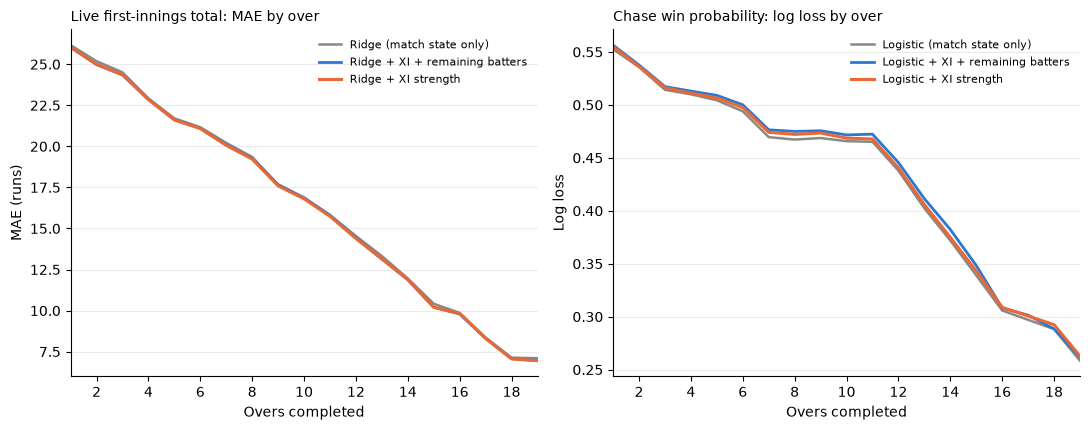

In [13]:
# ---- summary of validation findings: does the XI help? (ALL overs row) ----
def summary(cmp, task, unit):
    s = cmp[cmp["over"] == "ALL"][["challenger", "reference", "gain", "ci_lo", "ci_hi", "verdict"]].copy()
    s.insert(0, "task", task)
    s.insert(1, "unit", unit)
    return s

val_summary = pd.concat([summary(a_compare.assign(over="ALL"), "A. pre-match total", "runs"),
                         summary(b_compare, "B. live total", "runs"),
                         summary(c_compare, "C. chase win prob", "log loss")]).reset_index(drop=True)
print("Validation 2021-25, averaged over all overs (gain > 0 = XI helps):")
display(val_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
for ax, tbl, title, unit in ((axes[0], b_mae, "Live first-innings total: MAE by over", "MAE (runs)"),
                             (axes[1], c_ll, "Chase win probability: log loss by over", "Log loss")):
    for name, col, lw in zip(tbl.columns, (GRAY, BLUE, ORANGE), (1.8, 2.0, 2.2)):
        ax.plot(tbl.index, tbl[name], color=col, lw=lw, label=name)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("Overs completed"); ax.set_ylabel(unit)
    ax.set_xlim(1, 19); ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False, fontsize=8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "xi_features_validation.png", dpi=150)
plt.show()

## 11. Final holdout (2026) - evaluated once
Everything below is computed a single time. One season is a small sample, so read the confidence intervals, not the point estimates.

In [14]:
print("Holdout matches:", hold1["match_id"].nunique())

# Task A
a_models = PreMatchXI().fit(pm_dev)
a_hold = pd.concat([pd.DataFrame({"match_id": pm_hold["match_id"].to_numpy(), "over": 0, "model": n,
                                  "m": np.abs(p - pm_hold["final_score"].to_numpy())})
                    for n, p in ((A_BASE, pm_hold["base_pred"].to_numpy()), (A_XI, a_models.predict(pm_hold)))])
print("\nA. Pre-match MAE on 2026:")
print(a_hold.groupby("model")["m"].mean().round(2).to_string())
a_hold_cmp = compare(a_hold, [(A_XI, A_BASE)], overs=[0])
show_compare(a_hold_cmp, "MAE (runs)")

# Task B
b_hold = pd.concat([pd.DataFrame({"match_id": hold1["match_id"].to_numpy(), "over": hold1["over"].to_numpy(),
                                  "model": M.name, "m": np.abs(M().fit(dev1).predict_final(hold1) - hold1["final_score"].to_numpy())})
                    for M in MODELS_B])
print("\nB. Live first-innings MAE by over (2026):")
display(b_hold.pivot_table(index="over", columns="model", values="m", aggfunc="mean").loc[[o for o in CHECKPOINTS if o in set(b_hold["over"])]].round(2))
b_hold_cmp = compare(b_hold, PAIRS_B, overs=[o for o in CHECKPOINTS if o in set(b_hold["over"])] + ["ALL"])
show_compare(b_hold_cmp, "MAE (runs)")

# Task C
c_hold = pd.concat([chase_scores(hold2, M().fit(dev2).predict_proba1(hold2)).assign(model=M.name) for M in MODELS_C])
print("\nC. Chase log loss by over (2026):")
display(c_hold.pivot_table(index="over", columns="model", values="m", aggfunc="mean").loc[[o for o in CHECKPOINTS if o in set(c_hold["over"])]].round(3))
c_hold_cmp = compare(c_hold, PAIRS_C, overs=[o for o in CHECKPOINTS if o in set(c_hold["over"])] + ["ALL"])
show_compare(c_hold_cmp, "log loss")

hold_summary = pd.concat([summary(a_hold_cmp.assign(over="ALL"), "A. pre-match total", "runs"),
                          summary(b_hold_cmp, "B. live total", "runs"),
                          summary(c_hold_cmp, "C. chase win prob", "log loss")]).reset_index(drop=True)
print("\nHoldout 2026, averaged over all overs:")
display(hold_summary.round(3))
val_summary.to_csv(REPORTS_DIR / "xi_features_validation_summary.csv", index=False)
hold_summary.to_csv(REPORTS_DIR / "xi_features_holdout_summary.csv", index=False)

Holdout matches: 70

A. Pre-match MAE on 2026:
model
League + venue (no XI)    29.83
League + venue + XI       29.37

League + venue + XI  vs  League + venue (no XI)   (gain = reference MAE (runs) - challenger MAE (runs); 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
0,70,0.462,-0.462,1.362,noise



B. Live first-innings MAE by over (2026):


model,Ridge (match state only),Ridge + XI + remaining batters,Ridge + XI strength
over,,,
1,28.75,28.56,28.56
3,25.06,25.13,25.10
6,21.20,21.09,20.99
10,17.86,17.93,17.99
15,12.46,12.64,12.76
18,10.18,10.34,10.35



Ridge + XI strength  vs  Ridge (match state only)   (gain = reference MAE (runs) - challenger MAE (runs); 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,70,0.188,-0.383,0.791,noise
3,70,-0.044,-0.608,0.550,noise
6,70,0.215,-0.369,0.830,noise
10,70,-0.132,-0.730,0.469,noise
15,70,-0.294,-0.848,0.278,noise
18,69,-0.171,-0.775,0.442,noise
ALL,70,-0.011,-0.433,0.432,noise


... (10 outputs left out)


Logistic + XI + remaining batters  vs  Logistic (match state only)   (gain = reference log loss - challenger log loss; 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,70,-0.022,-0.051,0.004,noise
3,70,-0.017,-0.046,0.008,noise
6,70,-0.011,-0.030,0.007,noise
10,69,-0.011,-0.030,0.008,noise
15,65,-0.018,-0.041,0.002,noise
18,50,-0.013,-0.029,0.000,noise
ALL,70,-0.013,-0.031,0.003,noise



Holdout 2026, averaged over all overs:


,task,unit,challenger,reference,gain,ci_lo,ci_hi,verdict
0,A. pre-match total,runs,League + venue + XI,League + venue (no XI),0.462,-0.462,1.362,noise
1,B. live total,runs,Ridge + XI strength,Ridge (match state only),-0.011,-0.433,0.432,noise
2,B. live total,runs,Ridge + XI + remaining batters,Ridge + XI strength,0.035,-0.065,0.135,noise
3,B. live total,runs,Ridge + XI + remaining batters,Ridge (match state only),0.024,-0.401,0.495,noise
4,C. chase win prob,log loss,Logistic + XI strength,Logistic (match state only),-0.009,-0.026,0.006,noise
5,C. chase win prob,log loss,Logistic + XI + remaining batters,Logistic + XI strength,-0.004,-0.011,0.002,noise
6,C. chase win prob,log loss,Logistic + XI + remaining batters,Logistic (match state only),-0.013,-0.031,0.003,noise


## 12. See it: XI strength for real 2026 matches

In [15]:
ex = pm_hold.sort_values("date").tail(8)[["date", "team1", "team2", "xi1_bat", "xi2_bowl_runs", "xi2_bowl_wkts", "base_pred", "final_score"]].copy()
ex["xi_pred"] = a_models.predict(pm_hold.loc[ex.index])
ex["date"] = ex["date"].dt.date
print("xi1_bat = expected extra runs from the batting XI vs a typical XI; xi2_bowl_runs < 0 = tight bowling attack")
display(ex.rename(columns={"base_pred": "pre_match_baseline", "xi_pred": "pre_match_with_XI"}).round(1).reset_index(drop=True))

xi1_bat = expected extra runs from the batting XI vs a typical XI; xi2_bowl_runs < 0 = tight bowling attack


,date,team1,team2,xi1_bat,xi2_bowl_runs,xi2_bowl_wkts,pre_match_baseline,final_score,pre_match_with_XI
0,2026-05-22,Sunrisers Hyderabad,Royal Challengers Bengaluru,2.3,-2.1,-0.3,191.8,255.0,185.3
1,2026-05-23,Lucknow Super Giants,Punjab Kings,5.6,0.9,0.2,186.3,196.0,189.8
2,2026-05-24,Rajasthan Royals,Mumbai Indians,7.7,3.0,0.2,200.3,205.0,204.8
3,2026-05-24,Delhi Capitals,Kolkata Knight Riders,1.5,-4.7,-0.1,198.6,203.0,194.3
4,2026-05-26,Royal Challengers Bengaluru,Gujarat Titans,0.9,-2.4,0.1,211.5,254.0,210.6
5,2026-05-27,Rajasthan Royals,Sunrisers Hyderabad,7.2,0.1,0.4,191.0,243.0,198.9
6,2026-05-29,Rajasthan Royals,Gujarat Titans,7.9,-4.5,0.5,194.9,214.0,198.6
7,2026-05-31,Gujarat Titans,Royal Challengers Bengaluru,0.7,1.1,0.2,200.9,155.0,202.1


## Export for the dashboard
Writes `nb05.json` into `dashboard/public/data/` (override with the `IPL_DASHBOARD_DATA` environment variable). The React dashboard reads these files.
This cell only reads results that are already in memory, so run it **after** the cells above.

In [16]:
# ===== Dashboard export =====================================================================
# Writes JSON files that the React dashboard reads. Safe to re-run; it only writes files.
import json, datetime

DASH_DIR = Path(os.environ.get("IPL_DASHBOARD_DATA", PROJECT_ROOT / "dashboard" / "public" / "data"))
DASH_DIR.mkdir(parents=True, exist_ok=True)


def _clean(x):
    if isinstance(x, dict):
        return {str(k): _clean(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_clean(v) for v in x]
    if isinstance(x, pd.DataFrame):
        return _clean(x.reset_index().to_dict("records"))
    if isinstance(x, pd.Series):
        return _clean(x.to_dict())
    if isinstance(x, np.ndarray):
        return _clean(x.tolist())
    if isinstance(x, (bool, np.bool_)):
        return bool(x)
    if isinstance(x, (int, np.integer)):
        return int(x)
    if isinstance(x, (float, np.floating)):
        return round(float(x), 5) if np.isfinite(x) else None
    if isinstance(x, (pd.Timestamp, datetime.date)):
        return str(x)[:10]
    if x is None or isinstance(x, str):
        return x
    return str(x)


def tbl(df, scale=1.0):
    # pivot-style table -> {"index": [...], "columns": [...], "data": [[...]]}
    d = df.astype(float) * scale
    return {"index": _clean(list(d.index)), "columns": [str(c) for c in d.columns], "data": _clean(d.values.tolist())}


def recs(df):
    d = df.copy()
    for c in d.columns:
        if str(d[c].dtype).startswith("category") or d[c].dtype == object:
            d[c] = d[c].astype(str)
    return _clean(d.reset_index(drop=True).to_dict("records"))


def dash_save(name, payload):
    meta = {"notebook": name, "generated": datetime.datetime.now().isoformat(timespec="seconds"),
            "matches": int(len(matches)), "first_season": int(matches["season"].min()), "last_season": int(matches["season"].max())}
    path = DASH_DIR / (name + ".json")
    path.write_text(json.dumps(_clean({"meta": meta, **payload}), separators=(",", ":")), encoding="utf-8")
    print("wrote %s (%.0f KB)" % (path, path.stat().st_size / 1024))

big = pl[pl["bat_balls"] >= 600]
bigb = pl[pl["bowl_balls"] >= 600]
payload = {
    "validation_summary": recs(val_summary), "holdout_summary": recs(hold_summary),
    "a_compare": recs(a_compare), "b_compare": recs(b_compare), "c_compare": recs(c_compare),
    "b_holdout_compare": recs(b_hold_cmp), "c_holdout_compare": recs(c_hold_cmp), "a_holdout_compare": recs(a_hold_cmp),
    "b_mae_by_over": tbl(b_mae), "c_logloss_by_over": tbl(c_ll),
    "xi_correlation": recs(pm_dev[XI_PM + ["resid"]].corr()["resid"].drop("resid").rename("r").reset_index().rename(columns={"index": "feature"})),
    "xi_spread": {c: float(pm_dev[c].std()) for c in XI_PM},
    "top_batters": recs(big.sort_values("bat_ability", ascending=False).head(12)[["player", "matches", "bat_balls", "bat_ability"]]),
    "top_tight_bowlers": recs(bigb.sort_values("bowl_run_ability").head(12)[["player", "matches", "bowl_balls", "bowl_run_ability", "bowl_wk_ability"]]),
    "top_wicket_takers": recs(bigb.sort_values("bowl_wk_ability", ascending=False).head(12)[["player", "matches", "bowl_balls", "bowl_run_ability", "bowl_wk_ability"]]),
    "examples_2026": recs(ex.rename(columns={"base_pred": "pre_match_baseline"})),
}
dash_save("nb05", payload)

wrote c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\dashboard\public\data\nb05.json (25 KB)
